# Task 4: Skill Extraction & Feature Engineering

Run `python src/extract_skills.py` first. Uses `src/skill_taxonomy.py`, one shared taxonomy applied identically to all four companies. All outputs in `data/processed/` contain no description text, so they're safe to commit.

In [1]:
import sys, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
sys.path.insert(0, "../src")
from skill_taxonomy import TAXONOMY

P = "../data/processed/"
jobs = pd.read_csv(P + "job_skills.csv")
freq = pd.read_csv(P + "skill_frequency.csv")
cats = pd.read_csv(P + "category_share.csv", index_col=0)
emerging = pd.read_csv(P + "emerging_skills.csv")
print(f"{len(jobs)} postings, {sum(len(v) for v in TAXONOMY.values())} skills in {len(TAXONOMY)} categories")

5167 postings, 158 skills in 14 categories


## 1. Method

**Shared taxonomy, regex matching.** 158 skills in 14 categories. The list was seeded from the most common tech-looking terms in the actual postings (acronyms, CamelCase, `C++`-style tokens), then grouped. Matching runs on `cleaned_description` from Task 3, so boilerplate can't create fake skills.

Why regex, not an ML model: it's transparent (every match can be explained), needs no labelled training data, and the same rules apply to every company, which keeps the comparison fair. Fine-tuning a model is the brief's optional extra task.

**Ambiguous words** need exact-case or context rules, checked by reading samples of real matches:

In [2]:
examples = {
    "Go (language)": "Python, Go, Rust  ✓   |   go-to-market  ✗",
    "R (language)":  "Python, R, SQL  ✓     |   R&D  ✗",
    "Excel":         "Advanced Excel  ✓     |   excel at building relationships  ✗",
    "Transformers":  "Hugging Face Transformers  ✓   |   electrical transformer, feeder  ✗",
    "Embedded":      "embedded systems/firmware  ✓   |   embedded in the team  ✗",
    "AI alignment":  "Alignment team, AI safety  ✓   |   cross-functional alignment  ✗",
}
pd.Series(examples, name="matched ✓ / not matched ✗").to_frame()

,matched ✓ / not matched ✗
Go (language),"Python, Go, Rust ✓ | go-to-market ✗"
R (language),"Python, R, SQL ✓ | R&D ✗"
Excel,Advanced Excel ✓ | excel at building re...
Transformers,Hugging Face Transformers ✓ | electrical ...
Embedded,embedded systems/firmware ✓ | embedded in...
AI alignment,"Alignment team, AI safety ✓ | cross-funct..."


## 2. Top skills per company (share of postings that ask for each skill)

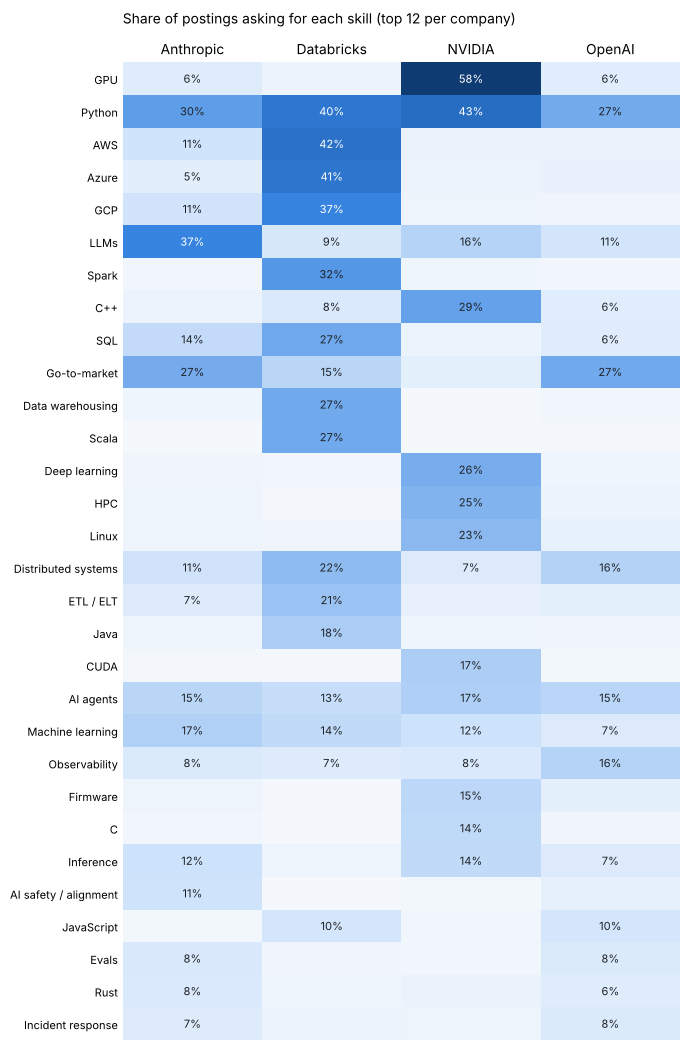

In [3]:
BLUE = LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
top = freq[freq["rank"] <= 12]["skill"].unique()
grid = (freq[freq.skill.isin(top)].pivot(index="skill", columns="company_name", values="share").fillna(0))
grid = grid.loc[grid.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 0.32 * len(grid) + 1))
ax.imshow(grid.values, cmap=BLUE, aspect="auto", vmin=0, vmax=0.6)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.35 else "#1f2328")
ax.set_xticks(range(grid.shape[1]), grid.columns); ax.xaxis.tick_top()
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=8)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("Share of postings asking for each skill (top 12 per company)", fontsize=10, pad=28, loc="left")
plt.tight_layout(); plt.show()

**Reading it:** each company has a clear fingerprint. NVIDIA is GPU/C++/HPC/CUDA; Databricks is cloud (AWS, Azure, GCP) plus Spark and SQL; Anthropic and OpenAI lead on LLMs, AI agents and go-to-market, reflecting heavy commercial hiring. Python is the one skill that's high everywhere.

## 3. Skill categories per company

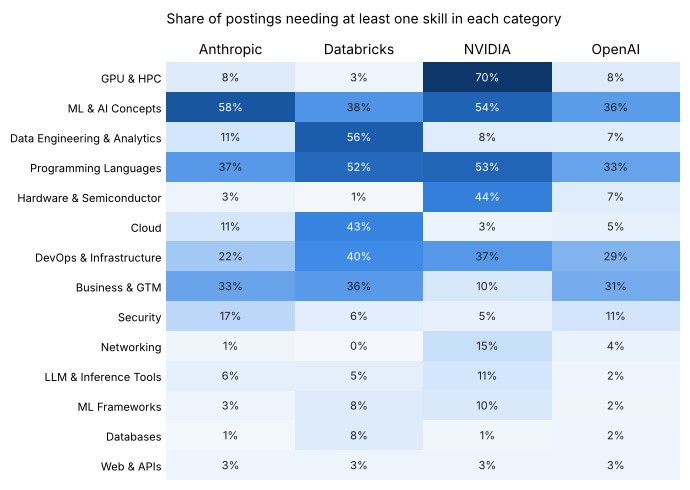

In [4]:
cs = cats.loc[cats.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(cs.values, cmap=BLUE, aspect="auto", vmin=0, vmax=0.7)
for i in range(cs.shape[0]):
    for j in range(cs.shape[1]):
        v = cs.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.4 else "#1f2328")
ax.set_xticks(range(cs.shape[1]), cs.columns); ax.xaxis.tick_top()
ax.set_yticks(range(cs.shape[0]), cs.index, fontsize=8)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("Share of postings needing at least one skill in each category", fontsize=10, pad=28, loc="left")
plt.tight_layout(); plt.show()

## 4. Role categories (from job titles)

In [5]:
pd.crosstab(jobs.role_category, jobs.company_name, normalize="columns").mul(100).round(0).sort_values("OpenAI", ascending=False)

company_name,Anthropic,Databricks,NVIDIA,OpenAI
role_category,,,,
Software Engineering,19.0,22.0,40.0,29.0
Solutions & Field,9.0,38.0,9.0,13.0
Sales & Partnerships,20.0,20.0,4.0,12.0
Research,12.0,1.0,4.0,9.0
Other,9.0,4.0,5.0,8.0
Program & Operations,6.0,2.0,3.0,7.0
Marketing & Comms,3.0,1.0,1.0,5.0
Corporate,7.0,3.0,1.0,4.0
Hardware Engineering,1.0,0.0,21.0,3.0


## 5. Emerging skills

A skill is flagged when its share in postings from the **last 90 days** is at least 1.5× its share in older postings, with at least 10 recent postings. ⚠️ Survivorship bias (Task 2): older postings that already closed are missing, so this is an early signal only. It gets more reliable as the twice-weekly snapshots build up.

In [6]:
e = emerging[emerging.emerging_skill_flag].sort_values("recent_postings", ascending=False)
e.groupby("company_name").head(5)[["company_name", "skill", "older_share", "recent_share", "recent_postings"]]

,company_name,skill,older_share,recent_share,recent_postings
316,NVIDIA,AI agents,0.0811,0.1836,438
317,NVIDIA,Inference,0.0946,0.1484,354
318,NVIDIA,Kubernetes,0.0784,0.1262,301
319,NVIDIA,PyTorch,0.0568,0.0943,225
320,NVIDIA,Observability,0.0162,0.0910,217
474,OpenAI,Go-to-market,0.1964,0.3131,170
158,Databricks,Salesforce,0.0439,0.1300,58
159,Databricks,Snowflake,0.0167,0.1278,57
160,Databricks,Generative AI,0.0774,0.1211,54
161,Databricks,Enterprise sales,0.0293,0.0987,44


## 6. Check: postings with no skills found

Expected to be mostly non-technical roles, where the taxonomy has little to match.

In [7]:
(jobs.n_skills == 0).groupby(jobs.role_category).mean().mul(100).round(0).sort_values().rename("% with no skills").to_frame()

,% with no skills
role_category,
Security,1.0
Data,2.0
ML / AI Engineering,3.0
Research,4.0
Software Engineering,4.0
Solutions & Field,5.0
Hardware Engineering,5.0
Sales & Partnerships,7.0
Product & Design,10.0
